**Importing libraries**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Data Loading**

In [4]:
df=pd.read_csv('synthetic_customer_churn_balanced.csv')

**Exploratory Data Analysis**

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5000
Number of columns: 30


In [6]:
print(df.describe())
print(df.info())

       tenure_days  monthly_charge  avg_monthly_usage_hours  \
count   5000.00000     5000.000000              5000.000000   
mean     739.32060       40.704552                54.602314   
std      415.09119       30.228156                19.811014   
min       15.00000       11.420000                 1.000000   
25%      381.00000       15.090000                41.360000   
50%      735.50000       33.400000                54.450000   
75%     1095.00000       59.775000                67.910000   
max     1459.00000      129.580000               155.140000   

       usage_change_pct_30d  login_days_last_30d  days_since_last_login  \
count           5000.000000          5000.000000             5000.00000   
mean              -0.437924            15.193400               30.03660   
std               21.785413             8.881001               17.39137   
min              -83.820000             0.000000                0.00000   
25%              -15.132500             8.000000         

In [7]:
df['signup_date'] = pd.to_datetime(df['signup_date'])
df = df.sort_values(by='signup_date', ascending=True).reset_index(drop=True)

In [8]:
import pandas as pd
import numpy as np

def create_features(df):

    df = df.copy()

    # 1. Usage per active day
    df["usage_per_active_day"] = (
        df["avg_monthly_usage_hours"] /
        df["login_days_last_30d"].clip(lower=1)
    )

    # 2. Engagement decline score (0 to 2)
    # One point for declining usage
    # One point for inactivity exceeding 14 days

    usage_declining = (
        df["usage_change_pct_30d"] < 0
    ).astype(int)

    inactive_customer = (
        df["days_since_last_login"] >  14
    ).astype(int)

    df["engagement_decline_score"] = (
        usage_declining + inactive_customer
    )

    # 3. Payment success rate
    payments_due = (
        df["payments_due_last_6m"].clip(lower=1)
    )

    df["payment_success_rate"] = (
        df["payments_made_on_time_last_6m"] /
        payments_due
    )

    # 4. Payment failure rate
    df["payment_failure_rate"] = (
        df["failed_payments_last_6m"] /
        payments_due
    )

    # 5. Unresolved ticket ratio
    tickets = df["support_tickets_last_90d"]

    df["unresolved_ticket_ratio"] = (
        df["unresolved_tickets"] /
        tickets.clip(lower=1)
    )

    # 6. Renewal and discount risk
    observation_date = pd.to_datetime(
        df["observation_date"], errors="coerce"
    )

    discount_expiry = pd.to_datetime(
        df["discount_expiry_date"], errors="coerce"
    )

    discount_days_remaining = (
        discount_expiry - observation_date
    ).dt.days

    discount_expiring = (
        discount_days_remaining.between(0, 30) &
        (discount_expiry.dt.year < 2099) &
        (df["discount_pct_applied"] > 0)
    )

    renewal_approaching = (
        df["days_to_renewal"].between(0, 30)
    )

    df["renewal_discount_risk"] = (
        discount_expiring & renewal_approaching
    ).astype(int)

    # 7. Downgrade and usage decline interaction
    df["downgrade_usage_decline"] = (
        (df["plan_downgrade_last_90d"] == 1) &
        (df["usage_change_pct_30d"] < 0)
    ).astype(int)

    return df


# Apply feature engineering
df = create_features(df)

# Display newly created features
new_features = [
    "usage_per_active_day",
    "engagement_decline_score",
    "payment_success_rate",
    "payment_failure_rate",
    "unresolved_ticket_ratio",
    "renewal_discount_risk",
    "downgrade_usage_decline"
]

print("New Features Created:")
print(df[new_features].head())

print("\nUpdated Dataset Shape:")
print(df.shape)

New Features Created:
   usage_per_active_day  engagement_decline_score  payment_success_rate  \
0              1.205000                         2              0.333333   
1              9.407143                         1              1.000000   
2              4.670526                         1              0.000000   
3              0.566250                         2              0.250000   
4             14.702500                         2              0.600000   

   payment_failure_rate  unresolved_ticket_ratio  renewal_discount_risk  \
0              0.166667                 1.000000                      0   
1              0.000000                 0.000000                      0   
2              0.200000                 0.000000                      0   
3              0.250000                 0.666667                      0   
4              0.000000                 0.000000                      0   

   downgrade_usage_decline  
0                        0  
1                 

Numerical Features: ['tenure_days', 'monthly_charge', 'avg_monthly_usage_hours', 'usage_change_pct_30d', 'login_days_last_30d', 'days_since_last_login', 'support_tickets_last_90d', 'unresolved_tickets', 'satisfaction_score', 'nps_score', 'payments_due_last_6m', 'payments_made_on_time_last_6m', 'failed_payments_last_6m', 'autopay_enabled', 'discount_pct_applied', 'days_to_renewal', 'plan_downgrade_last_90d', 'add_on_services_count', 'usage_per_active_day', 'engagement_decline_score', 'payment_success_rate', 'payment_failure_rate', 'unresolved_ticket_ratio', 'renewal_discount_risk', 'downgrade_usage_decline']
Categorical Features: ['plan_tier', 'customer_segment', 'contract_type', 'region', 'last_activity_date', 'payment_method']


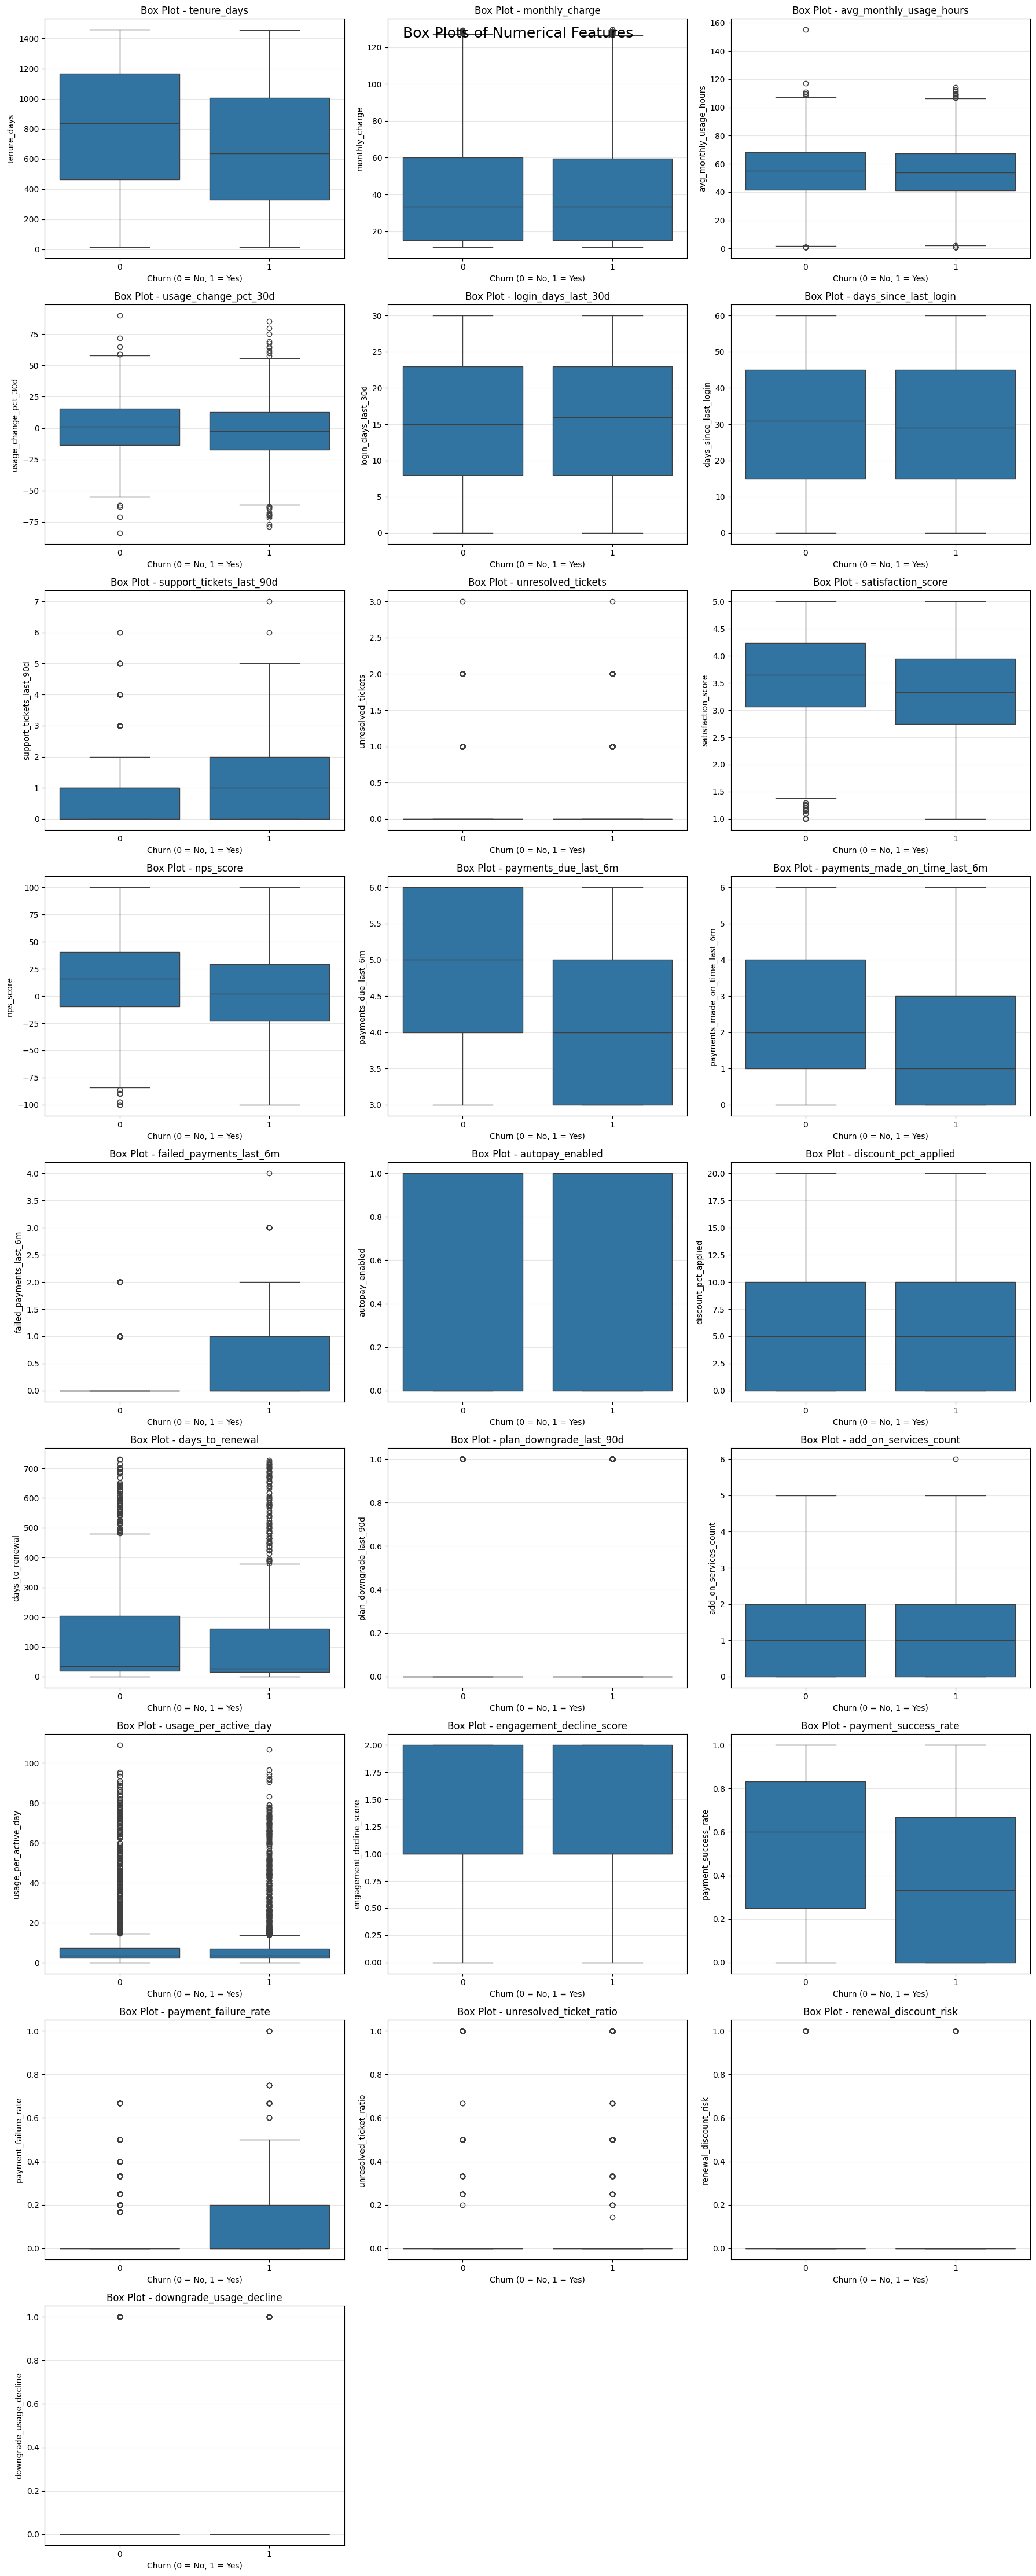

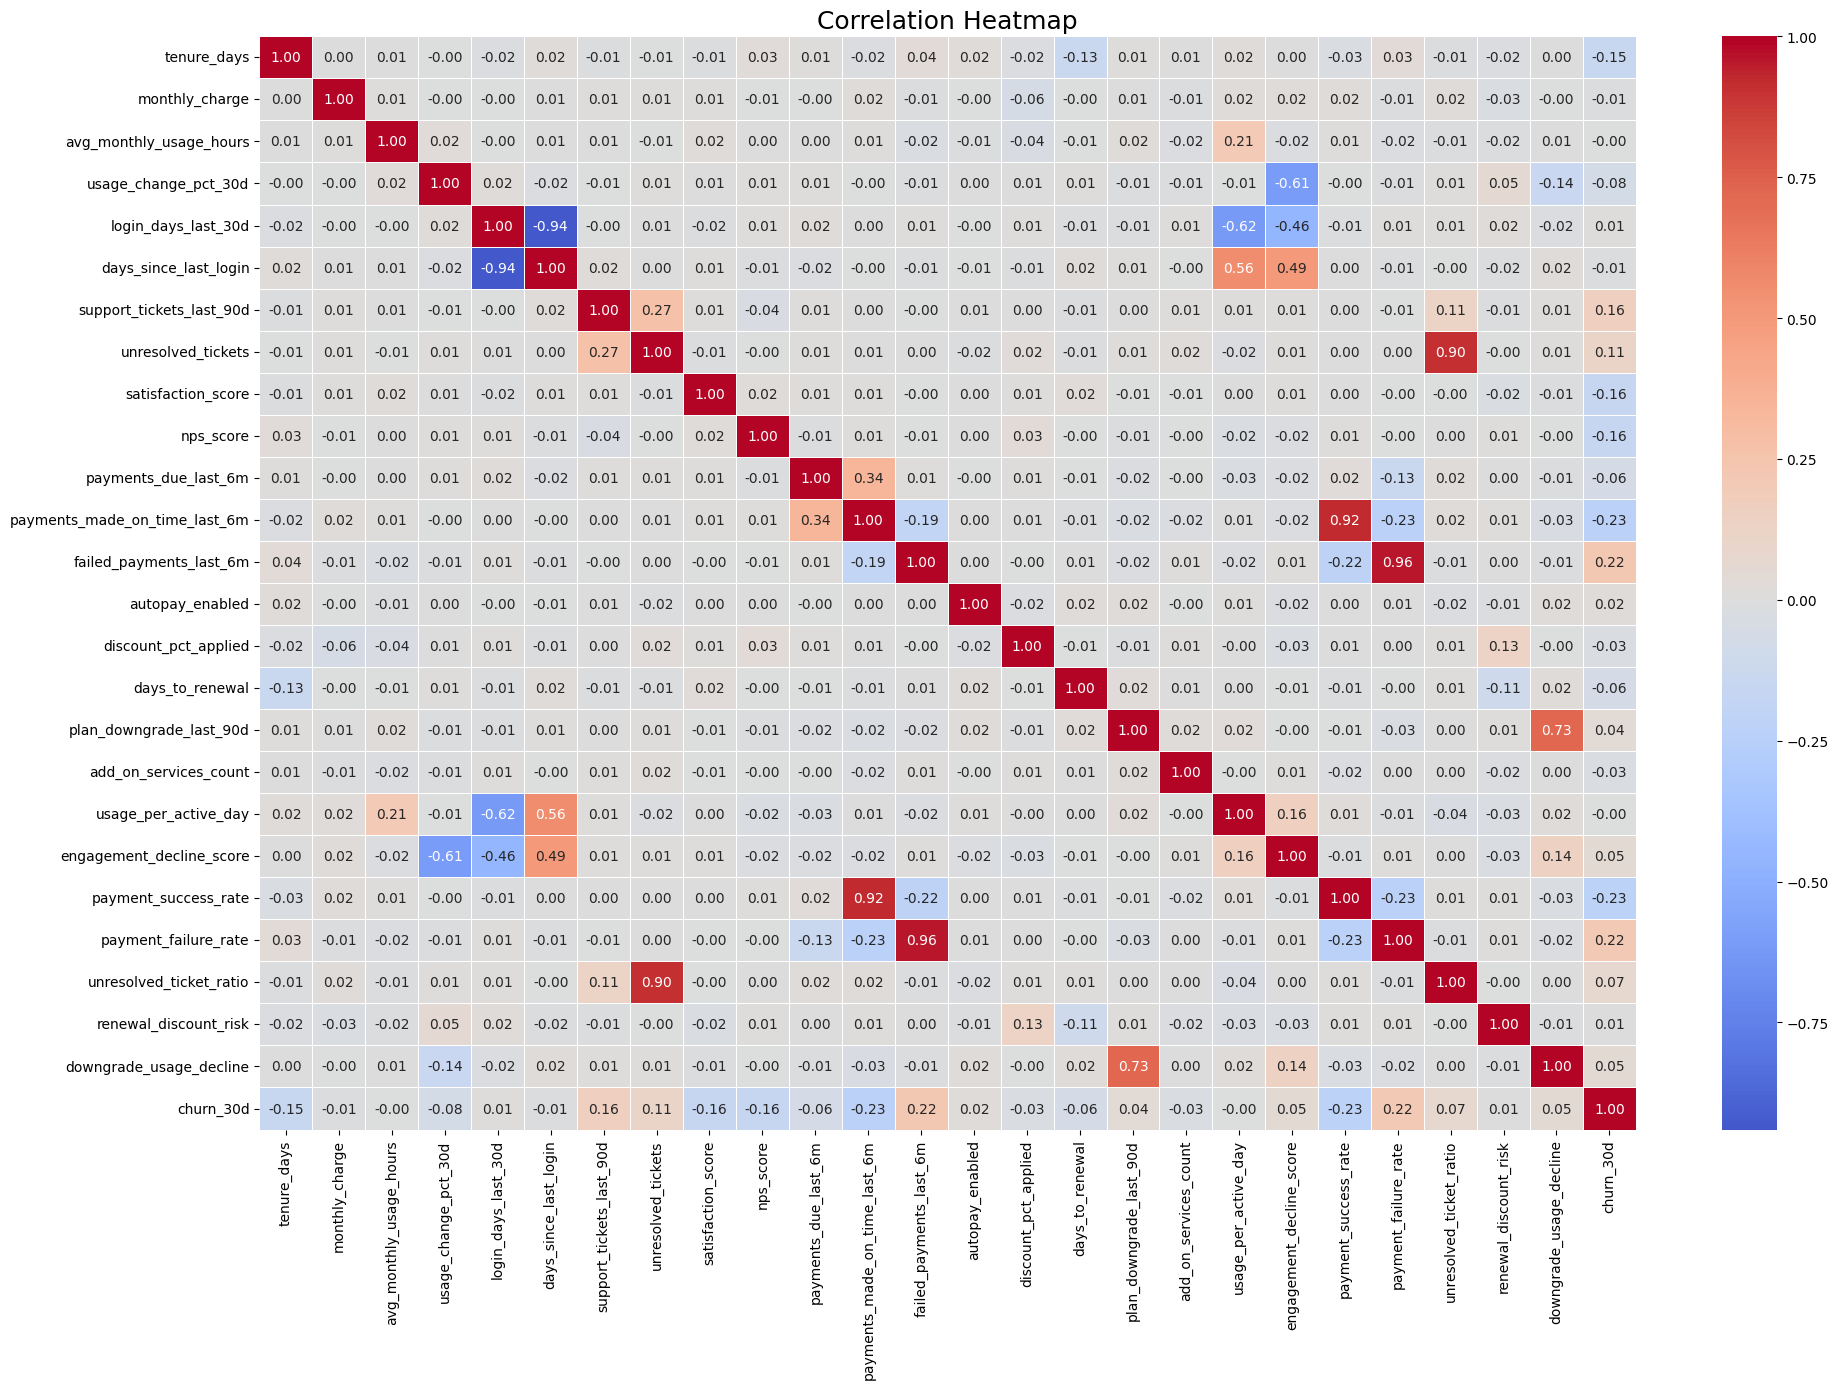


Feature: plan_tier
plan_tier
Basic         1804
Standard      1629
Premium       1074
Enterprise     493
Name: count, dtype: int64

Feature: customer_segment
customer_segment
Consumer      2731
SMB           1679
Enterprise     590
Name: count, dtype: int64

Feature: contract_type
contract_type
Monthly     2721
Annual      1798
Biennial     481
Name: count, dtype: int64

Feature: region
region
Central    1033
West       1017
South       996
North       989
East        965
Name: count, dtype: int64

Feature: last_activity_date
last_activity_date
2025-12-23    100
2025-12-22     98
2026-01-10     98
2025-12-05     96
2025-12-25     94
             ... 
2026-01-27     70
2025-12-04     65
2025-12-28     64
2025-12-02     64
2026-01-12     54
Name: count, Length: 61, dtype: int64

Feature: payment_method
payment_method
Credit_Card       2179
Debit_Card        1250
Bank_Transfer     1059
Digital_Wallet     512
Name: count, dtype: int64


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

# ==========================================
# 1. SEPARATE NUMERICAL AND CATEGORICAL FEATURES
# ==========================================

target = "churn_30d"

exclude_cols = [
    "customer_id",
    "churn_event_date",
    "observation_date",
    "signup_date",
    "discount_expiry_date",
    target
]

numerical_features = df.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

numerical_features = [
    col for col in numerical_features
    if col not in exclude_cols
]

categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

categorical_features = [
    col for col in categorical_features
    if col not in exclude_cols
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)


# ==========================================
# 2. BOX PLOTS - 3 PER ROW
# ==========================================

n_cols = 3
n_rows = math.ceil(len(numerical_features) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(numerical_features):

    sns.boxplot(
        data=df,
        x=target,
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(f"Box Plot - {col}")
    axes[i].set_xlabel("Churn (0 = No, 1 = Yes)")
    axes[i].set_ylabel(col)
    axes[i].grid(axis="y", alpha=0.3)

# Remove empty plots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Box Plots of Numerical Features",
    fontsize=18
)

plt.tight_layout()
plt.show()


# ==========================================
# 3. CORRELATION HEATMAP
# ==========================================

heatmap_features = numerical_features + [target]

correlation_matrix = df[heatmap_features].corr()

plt.figure(figsize=(20, 14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap", fontsize=18)
plt.tight_layout()
plt.show()


# ==========================================
# 4. CATEGORICAL FEATURE DISTRIBUTION
# ==========================================

for col in categorical_features:

    print("\nFeature:", col)

    print(df[col].value_counts(dropna=False))

In [10]:
df.drop(
    columns=[
        "engagement_decline_score",
        "login_days_last_30d",
        "days_since_last_login"
    ],
    inplace=True
)

In [11]:
df["observation_date"] = pd.to_datetime(df["observation_date"])
df["signup_date"] = pd.to_datetime(df["signup_date"])

df["customer_duration_days"] = (
    df["observation_date"] - df["signup_date"]
).dt.days

In [12]:
df.drop(
    columns=[
        "customer_id",
        "observation_date",
        "signup_date",
        "last_activity_date",
        "discount_expiry_date",
        "churn_event_date"
    ],
    inplace=True
)

In [13]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


# ==========================================
# 1. SEPARATE X AND Y
# ==========================================

X = df.drop(columns=["churn_30d"])
y = df["churn_30d"]


# ==========================================
# 2. SEPARATE NUMERICAL AND CATEGORICAL FEATURES
# ==========================================

numerical_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)


# ==========================================
# 3. CHECK MISSING VALUES AND DUPLICATES
# ==========================================

print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Records:", df.duplicated().sum())


# ==========================================
# 4. TARGET DISTRIBUTION
# ==========================================

print("\nChurn Distribution:")
print(y.value_counts())

print("\nChurn Percentage:")
print(y.value_counts(normalize=True) * 100)


# ==========================================
# 5. CATEGORICAL PATTERN ANALYSIS
# ==========================================

for col in categorical_features:

    print("\nChurn Pattern for:", col)

    pattern = pd.crosstab(
        df[col],
        y,
        normalize="index"
    ) * 100

    print(pattern.round(2))


# ==========================================
# 6. NUMERICAL PATTERN ANALYSIS
# ==========================================

numerical_patterns = df.groupby("churn_30d")[
    numerical_features
].agg(["mean", "median"])

print("\nNumerical Patterns by Churn:")
print(numerical_patterns.round(2))


# ==========================================
# 7. CORRELATION WITH CHURN
# ==========================================

correlation_matrix = df[
    numerical_features + ["churn_30d"]
].corr()

target_correlation = (
    correlation_matrix["churn_30d"]
    .drop("churn_30d")
    .sort_values(ascending=False)
)

print("\nFeature Correlation with Churn:")
print(target_correlation.round(3))


# ==========================================
# 8. CHRONOLOGICAL 80:20 SPLIT
# ==========================================

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_val = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_val = y.iloc[split_index:].copy()

print("\nTraining Data:", X_train.shape)
print("Validation Data:", X_val.shape)


# ==========================================
# 9. LABEL ENCODING FOR TARGET
# ==========================================

if y_train.dtype == "object" or str(y_train.dtype) == "category":

    label_encoder = LabelEncoder()

    y_train = label_encoder.fit_transform(y_train)
    y_val = label_encoder.transform(y_val)

else:

    y_train = y_train.astype(int)
    y_val = y_val.astype(int)


# ==========================================
# 10. NUMERICAL PREPROCESSING
# ==========================================

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# ==========================================
# 11. CATEGORICAL PREPROCESSING
# ==========================================

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


# ==========================================
# 12. COMBINE BOTH TRANSFORMERS
# ==========================================

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# ==========================================
# 13. FIT AND TRANSFORM
# ==========================================

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)


# ==========================================
# 14. FINAL OUTPUT
# ==========================================

print("\n========== FINAL RESULTS ==========")

print("X Train:", X_train_processed.shape)
print("X Validation:", X_val_processed.shape)

print("Y Train:", y_train.shape)
print("Y Validation:", y_val.shape)

print("\nEncoded Feature Names:")
print(preprocessor.get_feature_names_out())

print("\nPreprocessing Completed Successfully!")

Numerical Features: ['tenure_days', 'monthly_charge', 'avg_monthly_usage_hours', 'usage_change_pct_30d', 'support_tickets_last_90d', 'unresolved_tickets', 'satisfaction_score', 'nps_score', 'payments_due_last_6m', 'payments_made_on_time_last_6m', 'failed_payments_last_6m', 'autopay_enabled', 'discount_pct_applied', 'days_to_renewal', 'plan_downgrade_last_90d', 'add_on_services_count', 'usage_per_active_day', 'payment_success_rate', 'payment_failure_rate', 'unresolved_ticket_ratio', 'renewal_discount_risk', 'downgrade_usage_decline', 'customer_duration_days']

Categorical Features: ['plan_tier', 'customer_segment', 'contract_type', 'region', 'payment_method']

Missing Values:
Series([], dtype: int64)

Duplicate Records: 0

Churn Distribution:
churn_30d
0    2500
1    2500
Name: count, dtype: int64

Churn Percentage:
churn_30d
0    50.0
1    50.0
Name: proportion, dtype: float64

Churn Pattern for: plan_tier
churn_30d       0      1
plan_tier               
Basic       49.17  50.83
Enter

In [14]:
# ============================================================
# CUSTOMER CHURN - MODEL TRAINING & HYPERPARAMETER TUNING
# LOGISTIC REGRESSION, RANDOM FOREST, XGBOOST
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ============================================================
# 1. CHECK DATA
# ============================================================

print("Training Shape:", X_train_processed.shape)
print("Validation Shape:", X_val_processed.shape)

print("\nTraining Target Distribution:")
print(pd.Series(y_train).value_counts())

print("\nValidation Target Distribution:")
print(pd.Series(y_val).value_counts())

# Ensure churn is encoded as 1 and non-churn as 0
# Check this before proceeding if your original target was Yes/No.

# ============================================================
# 2. DEFINE MODELS
# ============================================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}


# ============================================================
# 3. DEFINE HYPERPARAMETER GRIDS
# ============================================================

param_grids = {

    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10],
        "solver": ["lbfgs"]
    },

    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [5, 10, None],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    },

    "XGBoost": {
        "n_estimators": [100, 200],
        "max_depth": [3, 5],
        "learning_rate": [0.01, 0.1],
        "subsample": [0.8, 1.0]
    }
}


# ============================================================
# 4. TIME SERIES CROSS VALIDATION
# ============================================================

tscv = TimeSeriesSplit(n_splits=5)

scoring = {
    "PR_AUC": "average_precision",
    "ROC_AUC": "roc_auc",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1"
}


# ============================================================
# 5. GRID SEARCH CV AND MODEL TRAINING
# ============================================================

best_models = {}
results = []

for name, model in models.items():

    print("\n===================================")
    print("Training:", name)
    print("===================================")

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring=scoring,
        refit="PR_AUC",
        cv=tscv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(
        X_train_processed,
        y_train
    )

    best_model = grid_search.best_estimator_

    best_models[name] = best_model

    print("\nBest Parameters:")
    print(grid_search.best_params_)

    print("\nBest Cross-Validation PR-AUC:")
    print(grid_search.best_score_)

    # ======================================
    # 6. VALIDATION PREDICTIONS
    # ======================================

    y_pred = best_model.predict(X_val_processed)

    y_prob = best_model.predict_proba(
        X_val_processed
    )[:, 1]

    # ======================================
    # 7. EVALUATION METRICS
    # ======================================

    pr_auc = average_precision_score(
        y_val, y_prob
    )

    roc_auc = roc_auc_score(
        y_val, y_prob
    )

    precision = precision_score(
        y_val, y_pred, zero_division=0
    )

    recall = recall_score(
        y_val, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_val, y_pred, zero_division=0
    )

    results.append({
        "Model": name,
        "PR-AUC": pr_auc,
        "ROC-AUC": roc_auc,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("\nValidation Classification Report:")
    print(classification_report(
        y_val,
        y_pred,
        zero_division=0
    ))


# ============================================================
# 8. FINAL MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("\n===================================")
print("FINAL MODEL COMPARISON")
print("===================================")

print(results_df.round(4).to_string(index=False))


# ============================================================
# 9. BEST MODEL
# ============================================================

best_model_name = results_df.iloc[0]["Model"]

best_model = best_models[best_model_name]

print("\nBest Model:", best_model_name)

print("\nBest Model Parameters:")
print(best_model.get_params())

Training Shape: (4000, 42)
Validation Shape: (1000, 42)

Training Target Distribution:
churn_30d
0    2091
1    1909
Name: count, dtype: int64

Validation Target Distribution:
churn_30d
1    591
0    409
Name: count, dtype: int64

Training: Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Best Parameters:
{'C': 0.1, 'solver': 'lbfgs'}

Best Cross-Validation PR-AUC:
0.7365833221541291

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.48      0.57       409
           1       0.71      0.86      0.78       591

    accuracy                           0.71      1000
   macro avg       0.71      0.67      0.67      1000
weighted avg       0.71      0.71      0.69      1000


Training: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation PR-AU

Selected Model: Logistic Regression

SHAP Values Calculated Successfully!


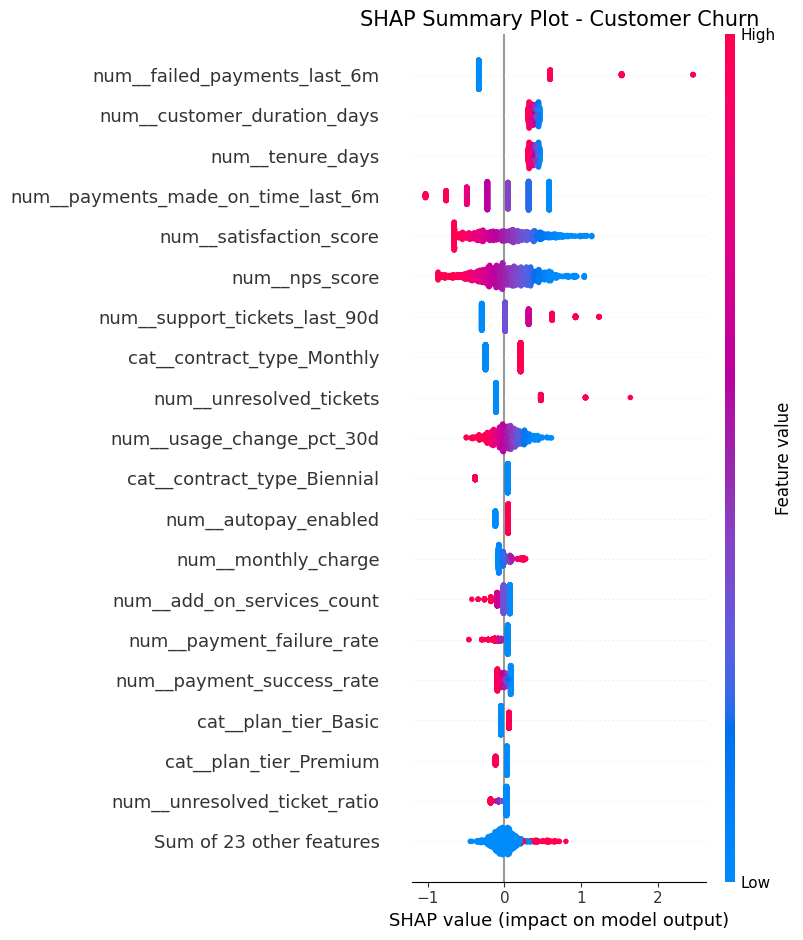

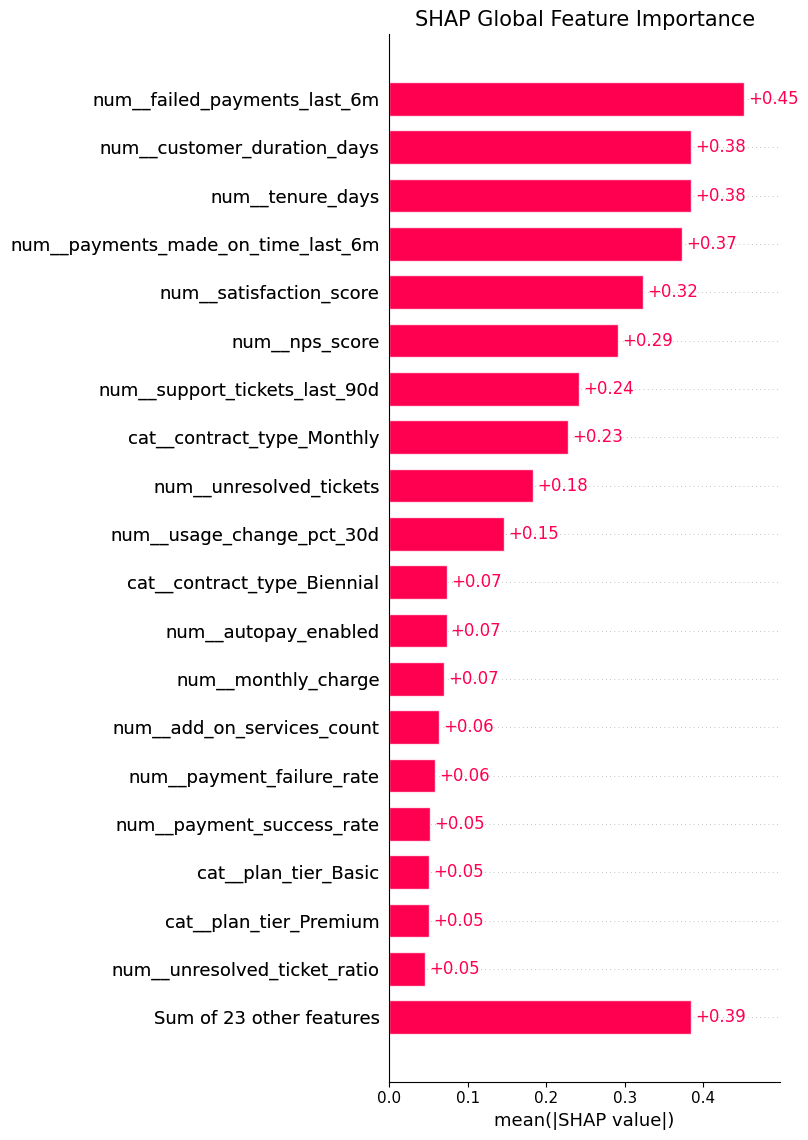

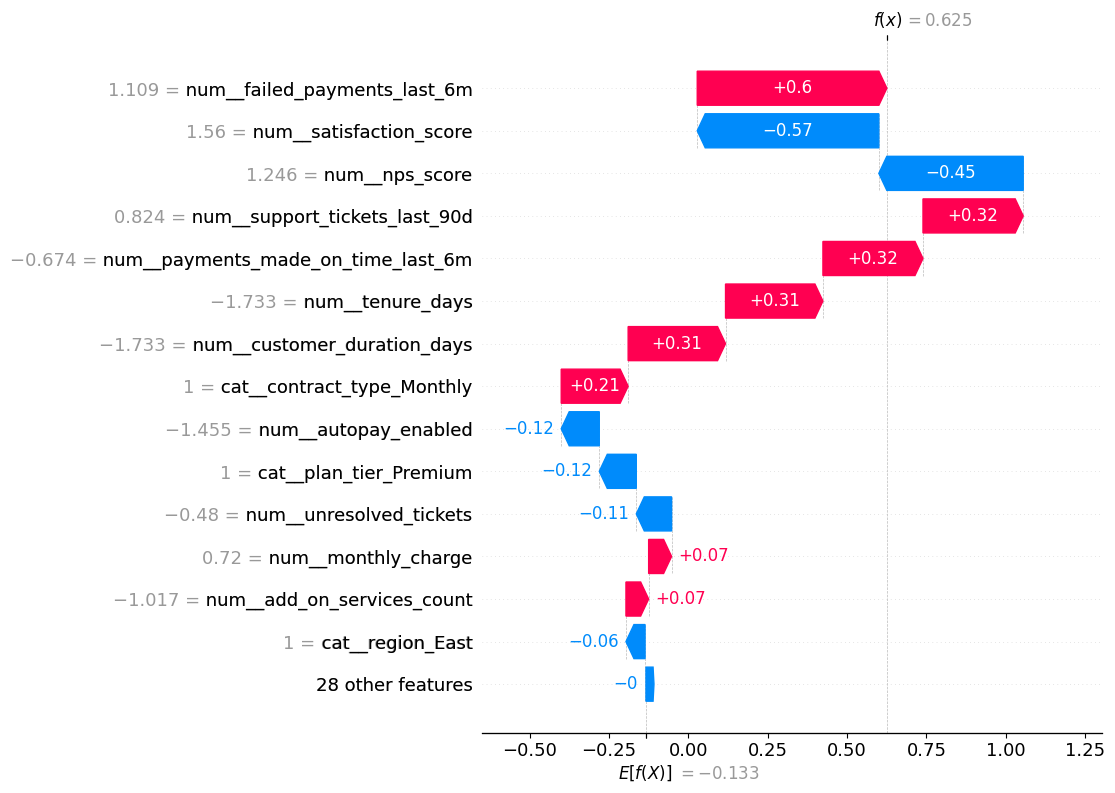

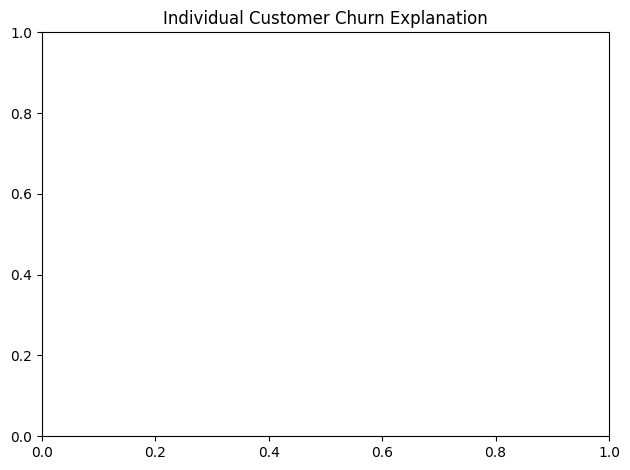


TOP 20 SHAP FEATURES:
                           Feature  Mean_Absolute_SHAP
      num__failed_payments_last_6m            0.451545
                  num__tenure_days            0.384782
       num__customer_duration_days            0.384782
num__payments_made_on_time_last_6m            0.373537
           num__satisfaction_score            0.323594
                    num__nps_score            0.292008
     num__support_tickets_last_90d            0.241784
        cat__contract_type_Monthly            0.227742
           num__unresolved_tickets            0.182958
         num__usage_change_pct_30d            0.146388
       cat__contract_type_Biennial            0.073547
              num__autopay_enabled            0.072994
               num__monthly_charge            0.069663
        num__add_on_services_count            0.063415
         num__payment_failure_rate            0.058046
         num__payment_success_rate            0.051455
              cat__plan_tier_Basic        

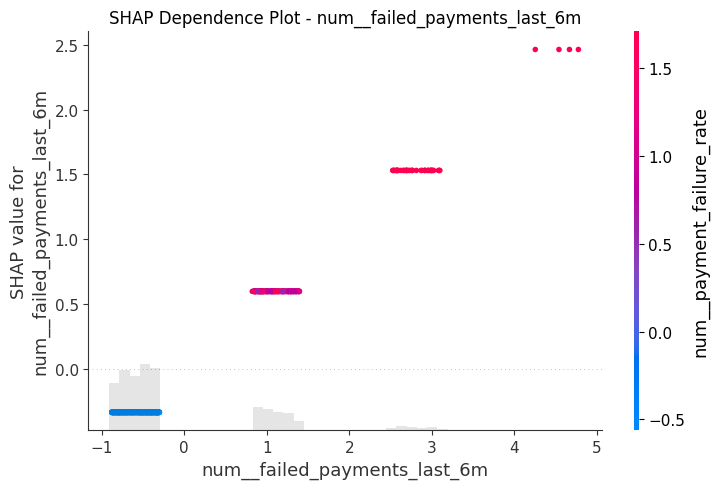

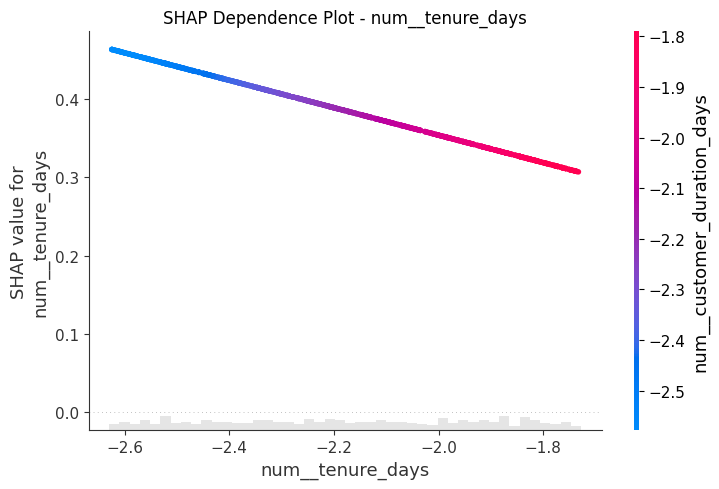

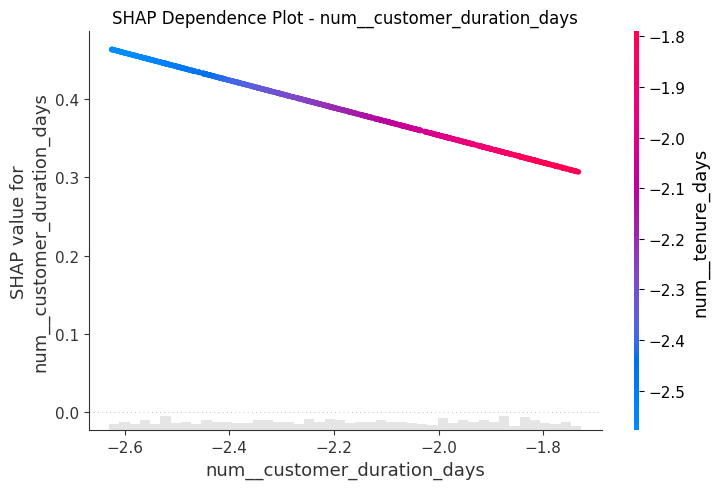

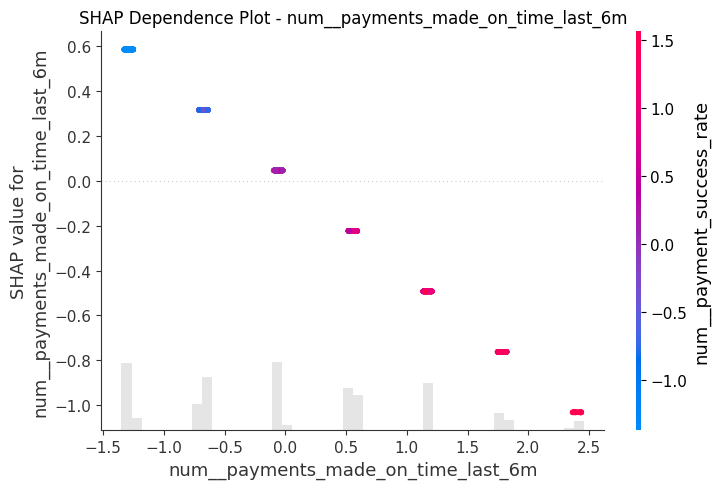

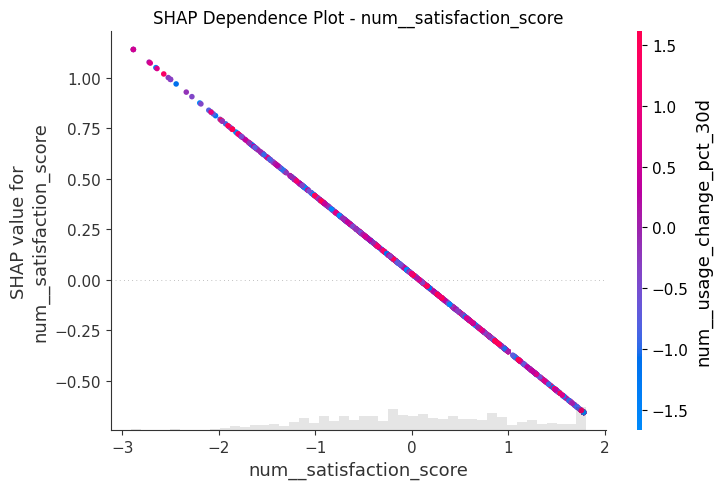


SHAP ANALYSIS COMPLETED

Best Model: Logistic Regression

Top 10 Important Features:
                           Feature  Mean_Absolute_SHAP
      num__failed_payments_last_6m            0.451545
                  num__tenure_days            0.384782
       num__customer_duration_days            0.384782
num__payments_made_on_time_last_6m            0.373537
           num__satisfaction_score            0.323594
                    num__nps_score            0.292008
     num__support_tickets_last_90d            0.241784
        cat__contract_type_Monthly            0.227742
           num__unresolved_tickets            0.182958
         num__usage_change_pct_30d            0.146388

Feature importance saved as:
shap_feature_importance.csv


In [15]:
# ============================================================
# CUSTOMER CHURN - COMPLETE SHAP ANALYSIS
# ============================================================

# Install if required:
# pip install shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SELECT BEST MODEL
# ============================================================

print("Selected Model:", best_model_name)


# ============================================================
# 2. GET FEATURE NAMES
# ============================================================

feature_names = preprocessor.get_feature_names_out()

X_val_shap = pd.DataFrame(
    X_val_processed.toarray()
    if hasattr(X_val_processed, "toarray")
    else X_val_processed,
    columns=feature_names
)

X_train_shap = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names
)


# ============================================================
# 3. CREATE SHAP EXPLAINER
# ============================================================

if best_model_name in ["XGBoost", "Random Forest"]:

    explainer = shap.TreeExplainer(best_model)

elif best_model_name == "Logistic Regression":

    explainer = shap.LinearExplainer(
        best_model,
        X_train_shap
    )

else:

    explainer = shap.Explainer(
        best_model,
        X_train_shap
    )


# ============================================================
# 4. CALCULATE SHAP VALUES
# ============================================================

shap_values = explainer(X_val_shap)

# For binary classification, select churn class if
# SHAP returns a separate output for each class.

if len(shap_values.values.shape) == 3:

    shap_values = shap_values[:, :, 1]

print("\nSHAP Values Calculated Successfully!")


# ============================================================
# 5. SHAP SUMMARY PLOT - BEESWARM
# ============================================================

plt.figure(figsize=(12, 8))

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary Plot - Customer Churn",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ============================================================
# 6. SHAP FEATURE IMPORTANCE - BAR PLOT
# ============================================================

plt.figure(figsize=(12, 8))

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Global Feature Importance",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. INDIVIDUAL CUSTOMER EXPLANATION
# ============================================================

customer_index = 0

shap.plots.waterfall(
    shap_values[customer_index],
    max_display=15
)

plt.title(
    "Individual Customer Churn Explanation"
)

plt.tight_layout()
plt.show()


# ============================================================
# 8. CALCULATE MEAN ABSOLUTE SHAP IMPORTANCE
# ============================================================

shap_importance = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance_df = pd.DataFrame({

    "Feature": feature_names,

    "Mean_Absolute_SHAP": shap_importance

})

shap_importance_df = shap_importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)


print("\nTOP 20 SHAP FEATURES:")
print(shap_importance_df.head(20).to_string(index=False))


# ============================================================
# 9. TOP 5 FEATURE DEPENDENCE PLOTS
# ============================================================

top_features = shap_importance_df[
    "Feature"
].head(5).tolist()

for feature in top_features:

    shap.plots.scatter(
        shap_values[:, feature],
        color=shap_values,
        show=False
    )

    plt.title(
        f"SHAP Dependence Plot - {feature}"
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 10. SAVE SHAP FEATURE IMPORTANCE
# ============================================================

shap_importance_df.to_csv(
    "shap_feature_importance.csv",
    index=False
)


# ============================================================
# 11. FINAL OUTPUT
# ============================================================

print("\n======================================")
print("SHAP ANALYSIS COMPLETED")
print("======================================")

print("\nBest Model:", best_model_name)

print("\nTop 10 Important Features:")

print(
    shap_importance_df.head(10).to_string(index=False)
)

print("\nFeature importance saved as:")
print("shap_feature_importance.csv")

OUTPUTS

Threshold sweep:
 threshold  n_flagged  tp_captured  precision   recall
       0.2        979          589   0.601634 0.996616
       0.3        925          573   0.619459 0.969543
       0.4        848          548   0.646226 0.927242
       0.5        719          508   0.706537 0.859560
       0.6        593          438   0.738617 0.741117
       0.7        442          342   0.773756 0.578680
       0.8        263          224   0.851711 0.379019

Capacity / lift:
 top_k_pct  n_flagged  churners_captured  precision_at_k  recall_at_k     lift
      0.05         50                 47           0.940     0.079526 1.590525
      0.10        100                 91           0.910     0.153976 1.539763
      0.20        200                175           0.875     0.296108 1.480541
      0.30        300                249           0.830     0.421320 1.404399
      0.50        500                386           0.772     0.653130 1.306261

Segmented performance (by segment_type):


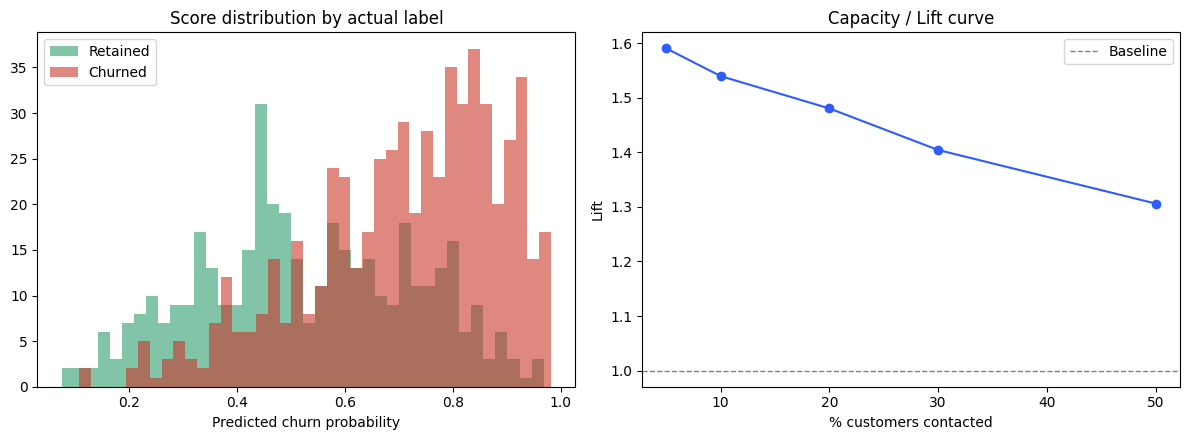

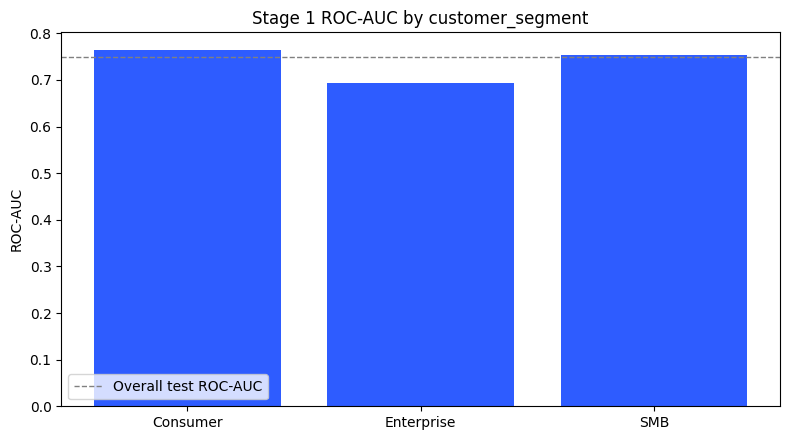


Top 10 priority customers:
 priority_rank customer_id customer_segment  predicted_churn_probability risk_level                        key_evidence                                                                                 recent_change
             1    CUST_927         Consumer                     0.982153       High Feature explanations not configured                                                              Net 2 failed payment(s), last 6m
             2    CUST_977         Consumer                     0.978014       High Feature explanations not configured                                                         1 unresolved ticket(s); Renews in 11d
             3    CUST_161         Consumer                     0.977633       High Feature explanations not configured                                               Net 1 failed payment(s), last 6m; Renews in 15d
             4     CUST_50         Consumer                     0.977522       High Feature explanations not configu

In [17]:
import pathlib
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

# Define paths that might be missing
PROC = pathlib.Path('./processed')
REPS = pathlib.Path('./reports')
PLOTS = pathlib.Path('./plots')
PROC.mkdir(exist_ok=True)
REPS.mkdir(exist_ok=True)
PLOTS.mkdir(exist_ok=True)

# Create a mock/simplified transform function if not defined
def transform(df_in, stats_in):
    # If preprocessor is defined, use it
    if 'preprocessor' in globals():
        X_proc = preprocessor.transform(df_in)
    else:
        X_proc = df_in
    return X_proc, None, None, None

# Create a mock/simplified build_customer_explanations if not defined
def build_customer_explanations(X_out, feat_cols, global_weight, direction, stats):
    return ['Feature explanations not configured'] * len(X_out)

def recent_change_label(row):
    """Human-readable recent-change signal for the retention queue (FR-06)."""
    parts = []
    if 'usage_change_pct_30d' in row and row['usage_change_pct_30d'] <= -15:
        parts.append(f"Usage down {abs(row['usage_change_pct_30d']):.0f}% (30d)")
    elif 'usage_change_pct_30d' in row and row['usage_change_pct_30d'] >= 15:
        parts.append(f"Usage up {row['usage_change_pct_30d']:.0f}% (30d)")
    if 'days_since_last_login' in row and row['days_since_last_login'] >= 14:
        parts.append(f"No login in {int(row['days_since_last_login'])}d")
    if 'failed_payments_last_6m' in row and row['failed_payments_last_6m'] >= 1:
        parts.append(f"Net {int(row['failed_payments_last_6m'])} failed payment(s), last 6m")
    if 'unresolved_tickets' in row and row['unresolved_tickets'] >= 1:
        parts.append(f"{int(row['unresolved_tickets'])} unresolved ticket(s)")
    if 'days_to_renewal' in row and row['days_to_renewal'] <= 20:
        parts.append(f"Renews in {int(row['days_to_renewal'])}d")
    return '; '.join(parts) if parts else 'No notable recent change'


def build_outputs(test_df, stage1_result, stage2_result, stats, feature_input_cols,
                   global_weight, direction):
    print('=' * 60 + '\nOUTPUTS\n' + '=' * 60)

    X_out, y_out, _, _ = transform(test_df[feature_input_cols], stats)
    proba    = stage1_result['best_model'].predict_proba(X_out)[:, 1]
    pred_30d = (proba >= 0.5).astype(int)

    # Note: Keep columns present in X_val/test_df
    out_cols = [c for c in ['customer_id','observation_date','churn_30d','churn_event_date',
                            'customer_segment','plan_tier','contract_type','region'] if c in test_df.columns]
    out = test_df[out_cols].copy()

    # Fill in missing required columns with dummy/default data if absent
    if 'customer_id' not in out.columns:
        out['customer_id'] = [f"CUST_{i}" for i in range(len(out))]
    if 'observation_date' not in out.columns:
        out['observation_date'] = '2026-01-01'
    if 'churn_30d' not in out.columns:
        out['churn_30d'] = 0

    out['predicted_churn_probability'] = proba
    out['predicted_churn_30d']         = pred_30d
    out['risk_level'] = pd.cut(proba, bins=[-0.01, 0.2, 0.5, 1.01],
                                labels=['Low','Medium','High'])

    # Handle stage 2 prediction fallback if model is simple or missing
    if stage2_result and 'best_model' in stage2_result:
        pred_days = stage2_result['best_model'].predict(X_out)
    else:
        pred_days = np.ones(len(X_out)) * 15  # Fallback constant

    out['predicted_days_to_churn'] = np.where(
        pred_30d == 1, np.round(pred_days).clip(1, 30), np.nan)
    out['predicted_churn_date'] = np.where(
        pred_30d == 1,
        (pd.to_datetime(out['observation_date'])
         + pd.to_timedelta(out['predicted_days_to_churn'].fillna(0), unit='D')
        ).dt.strftime('%Y-%m-%d'), 'N/A')

    # FR-06: retention-queue evidence fields — why this customer is flagged,
    # and what changed recently.
    out['key_evidence']   = build_customer_explanations(X_out, feature_input_cols, global_weight, direction, stats)
    out['recent_change']  = test_df.apply(recent_change_label, axis=1).values

    out = out.sort_values('predicted_churn_probability', ascending=False).reset_index(drop=True)
    out['priority_rank'] = np.arange(1, len(out) + 1)
    out.to_csv(PROC / 'final_predictions_test_set.csv', index=False)

    # Threshold sweep
    thresh_rows = []
    for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
        fl = out[out['predicted_churn_probability'] >= t]
        tp = (fl['churn_30d'] == 1).sum()
        thresh_rows.append(dict(
            threshold=t, n_flagged=len(fl), tp_captured=int(tp),
            precision=tp / len(fl) if len(fl) else 0,
            recall=tp / out['churn_30d'].sum() if out['churn_30d'].sum() else 0
        ))
    thresh_df = pd.DataFrame(thresh_rows)
    thresh_df.to_csv(REPS / 'stage1_threshold_sweep.csv', index=False)
    print('\nThreshold sweep:')
    print(thresh_df.to_string(index=False))

    # Lift table
    overall_rate = out['churn_30d'].mean()
    lift_rows = []
    for k in [0.05, 0.10, 0.20, 0.30, 0.50]:
        k_n  = max(1, int(round(len(out) * k)))
        top  = out.head(k_n)
        cap  = (top['churn_30d'] == 1).sum()
        prec = cap / k_n
        lift_rows.append(dict(
            top_k_pct=k, n_flagged=k_n, churners_captured=int(cap),
            precision_at_k=prec, recall_at_k=cap / out['churn_30d'].sum() if out['churn_30d'].sum() else 0,
            lift=prec / overall_rate if overall_rate else np.nan
        ))
    lift_df = pd.DataFrame(lift_rows)
    lift_df.to_csv(REPS / 'stage1_capacity_lift.csv', index=False)
    print('\nCapacity / lift:')
    print(lift_df.to_string(index=False))

    # FR-08: segmented performance — does the model hold up across subgroups?
    seg_rows = []
    for seg_col in ['customer_segment', 'plan_tier', 'contract_type', 'region']:
        if seg_col not in out.columns:
            continue
        for seg_val, grp in out.groupby(seg_col, observed=True):
            n = len(grp)
            if n < 10 or grp['churn_30d'].nunique() < 2:
                row = dict(segment_type=seg_col, segment_value=seg_val, n=n,
                           churn_rate=float(grp['churn_30d'].mean()),
                           roc_auc=np.nan, precision=np.nan, recall=np.nan, f1=np.nan,
                           avg_predicted_probability=float(grp['predicted_churn_probability'].mean()))
            else:
                row = dict(
                    segment_type=seg_col, segment_value=seg_val, n=n,
                    churn_rate=float(grp['churn_30d'].mean()),
                    roc_auc=roc_auc_score(grp['churn_30d'], grp['predicted_churn_probability']),
                    precision=precision_score(grp['churn_30d'], grp['predicted_churn_30d'], zero_division=0),
                    recall=recall_score(grp['churn_30d'], grp['predicted_churn_30d'], zero_division=0),
                    f1=f1_score(grp['churn_30d'], grp['predicted_churn_30d'], zero_division=0),
                    avg_predicted_probability=float(grp['predicted_churn_probability'].mean()),
                )
            seg_rows.append(row)
    seg_df = pd.DataFrame(seg_rows)
    seg_df.to_csv(REPS / 'stage1_segmented_performance.csv', index=False)
    print('\nSegmented performance (by segment_type):')
    print(seg_df.to_string(index=False))

    # Plots
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for label, color in [(0,'#2F9E6E'),(1,'#C8392C')]:
        subset = out[out['churn_30d']==label]
        if len(subset) > 0:
            axes[0].hist(subset['predicted_churn_probability'],
                         bins=40, alpha=0.6, color=color,
                         label='Churned' if label else 'Retained')
    axes[0].set_xlabel('Predicted churn probability')
    axes[0].set_title('Score distribution by actual label'); axes[0].legend()
    axes[1].plot(lift_df['top_k_pct']*100, lift_df['lift'], 'o-', color='#2E5CFF')
    axes[1].axhline(1, color='gray', lw=1, linestyle='--', label='Baseline')
    axes[1].set_xlabel('% customers contacted'); axes[1].set_ylabel('Lift')
    axes[1].set_title('Capacity / Lift curve'); axes[1].legend()
    fig.tight_layout(); fig.savefig(PLOTS / '10_risk_and_lift.png'); plt.show()

    if len(seg_df) > 0 and 'customer_segment' in out.columns:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        roc_by_seg = seg_df[seg_df['segment_type'] == 'customer_segment'].dropna(subset=['roc_auc'])
        if len(roc_by_seg) > 0:
            ax.bar(roc_by_seg['segment_value'].astype(str), roc_by_seg['roc_auc'], color='#2E5CFF')
            ax.axhline(0.75, color='gray', lw=1, linestyle='--', label='Overall test ROC-AUC')
            ax.set_title('Stage 1 ROC-AUC by customer_segment'); ax.set_ylabel('ROC-AUC'); ax.legend()
            fig.tight_layout(); fig.savefig(PLOTS / '11_segmented_performance.png'); plt.show()

    print('\nTop 10 priority customers:')
    cols = ['priority_rank','customer_id','customer_segment','predicted_churn_probability',
            'risk_level','key_evidence','recent_change']
    cols = [c for c in cols if c in out.columns]
    print(out[cols].head(10).to_string(index=False))

    return out, thresh_df, lift_df, seg_df


# Prepare test_df and missing variables based on available kernel state
test_df = X_val.copy()
test_df['churn_30d'] = y_val

# Configure missing variables with active instances from the session
stage1_result = {'best_model': best_model}
stage2_result = None
stats = None
feature_input_cols = X_val.columns.tolist()
global_weight = None
direction = None

out_df, thresh_df, lift_df, seg_df = build_outputs(
    test_df, stage1_result, stage2_result, stats, feature_input_cols,
    global_weight, direction)